# Лабораторна робота №4: Інженерія даних для задачі класифікації

**Дисципліна:** Методи та технології інженерії даних  
**Виконав:** студент 2-го курсу  
**Датасет:** Automobile Data (205 рядків, 26 характеристик)  
**Цільова змінна:** `symboling` (страховий коефіцієнт ризику автомобіля від -2 до +3)  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Stanislavwx/Methods-and-Technologies-of-Data-Engineering/blob/main/Lab4/Lab4.ipynb)


## Мета роботи
Навчитися виконувати підготовку та перетворення даних для задачі класифікації, формувати різні набори ознак, застосовувати метод головних компонент (PCA) та досліджувати вплив інженерії даних на якість моделі машинного навчання.


In [1]:
# 1. Імпорт необхідних бібліотек
import os
import warnings
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)
from imblearn.over_sampling import SMOTE

# Налаштування візуалізації
%matplotlib inline
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (10, 5)


## Завдання 1. Підготовка даних за результатами EDA
1. Завантажити набір даних `Automobile_data.csv`.
2. Перевірити типи даних та замінити символ `'?'` на `np.nan`.
3. Обробити пропущені значення: для числових колонок — медіаною, для категоріальних — модою.
4. Перевірити наявність дублікатів та усунути їх за потреби.
5. Визначити цільову змінну $y$ (`symboling`) та початковий набір ознак $X$.


In [2]:
# 1.1 Завантаження даних
df = pd.read_csv('Automobile_data.csv')
print(f"Розмір вихідного датасету: {df.shape[0]} рядків, {df.shape[1]} стовпців")

# 1.2 Заміна '?' на NaN
df = df.replace('?', np.nan)

# Визначення числових та категоріальних ознак
numeric_columns = [
    'normalized-losses', 'wheel-base', 'length', 'width', 'height',
    'curb-weight', 'engine-size', 'bore', 'stroke', 'compression-ratio',
    'horsepower', 'peak-rpm', 'city-mpg', 'highway-mpg', 'price'
]

categorical_columns = [
    'make', 'fuel-type', 'aspiration', 'num-of-doors', 'body-style',
    'drive-wheels', 'engine-location', 'engine-type', 'num-of-cylinders',
    'fuel-system'
]

# 1.3 Приведення числових ознак до типу float
for col in numeric_columns:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Заповнення пропусків
for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_columns:
    if df[col].isnull().sum() > 0:
        df[col] = df[col].fillna(df[col].mode()[0])

# 1.4 Перевірка на дублікати та пропуски
print(f"Кількість дублікатів: {df.duplicated().sum()}")
print(f"Залишок пропусків у даних: {df.isnull().sum().sum()}")

# 1.5 Формування X та y
target_col = 'symboling'
X = df.drop(columns=[target_col])
y = df[target_col]

print(f"Розмірність матриці X: {X.shape}")
print(f"Унікальні класи цільової змінної y: {sorted(y.unique())}")
df.head(3)


Розмір вихідного датасету: 205 рядків, 26 стовпців
Кількість дублікатів: 0
Залишок пропусків у даних: 0
Розмірність матриці X: (205, 25)
Унікальні класи цільової змінної y: [np.int64(-2), np.int64(-1), np.int64(0), np.int64(1), np.int64(2), np.int64(3)]


,symboling,normalized-losses,make,fuel-type,aspiration,num-of-doors,body-style,drive-wheels,engine-location,wheel-base,...,engine-size,fuel-system,bore,stroke,compression-ratio,horsepower,peak-rpm,city-mpg,highway-mpg,price
0,3,115.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,13495.0
1,3,115.0,alfa-romero,gas,std,two,convertible,rwd,front,88.6,...,130,mpfi,3.47,2.68,9.0,111.0,5000.0,21,27,16500.0
2,1,115.0,alfa-romero,gas,std,two,hatchback,rwd,front,94.5,...,152,mpfi,2.68,3.47,9.0,154.0,5000.0,19,26,16500.0


## Завдання 2. Формування навчальної та тестової вибірок
- Розподілити дані на навчальну та тестову вибірки у співвідношенні 80% / 20%.
- Застосувати стратифікований поділ (`stratify=y`), щоб зберегти пропорції всіх класів (особливо міноритарного класу `-2`, де лише 3 об'єкти).
- Тестова вибірка ізолюється до фінального оцінювання.


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print(f"Розмір X_train: {X_train.shape[0]} об'єктів")
print(f"Розмір X_test:  {X_test.shape[0]} об'єктів")
print("\nРозподіл класів у train-вибірці:")
display(y_train.value_counts().sort_index().to_frame(name='Кількість'))


Розмір X_train: 164 об'єктів
Розмір X_test:  41 об'єктів

Розподіл класів у train-вибірці:


,Кількість
symboling,
-2,2
-1,18
0,54
1,43
2,25
3,22


## Завдання 3. Підготовка числових і категоріальних ознак
- Числові ознаки масштабуються за допомогою `StandardScaler` ($\mu=0, \sigma=1$).
- Категоріальні ознаки кодуються через `OneHotEncoder(handle_unknown='ignore')`.
- Об'єднання у конвеєр за допомогою `ColumnTransformer`.
- **Важливо:** `fit` виконується виключно на train-вибірці, щоб уникнути витоку даних (`data leakage`).


In [4]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numeric_columns),
        ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), categorical_columns)
    ]
)

# Навчання препроцесора тільки на train
X_train_prep = preprocessor.fit_transform(X_train)
X_test_prep = preprocessor.transform(X_test)

feature_names = preprocessor.get_feature_names_out()
print(f"Кількість ознак після One-Hot кодування: {X_train_prep.shape[1]}")


Кількість ознак після One-Hot кодування: 73


## Завдання 4. Аналіз дисбалансу цільової змінної та балансування
- Аналіз часток кожного класу в навчальній вибірці.
- Виявлено суттєвий дисбаланс (від 1.2% до 32.9%).
- Застосування алгоритму `SMOTE` (з `k_neighbors=1`) виключно для навчальної вибірки.
- Тестова вибірка залишається незалежною і не балансується.


,Кількість об'єктів,Частка (%)
symboling,,
-2,2,1.22
-1,18,10.98
0,54,32.93
1,43,26.22
2,25,15.24
3,22,13.41


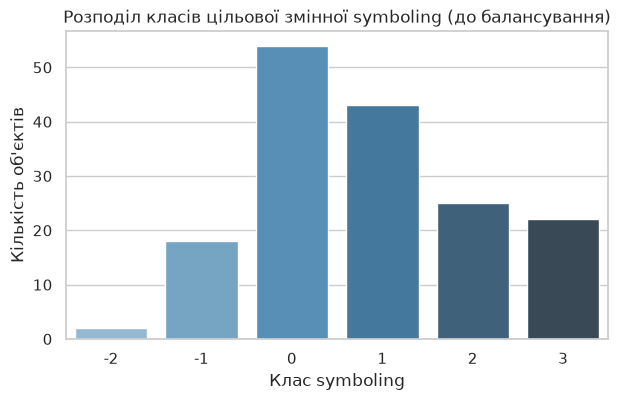

Розмір train до балансування: 164 рядків
Розмір train після SMOTE:     324 рядків (по 54 зразки на кожен клас)


In [5]:
# Аналіз розподілу класів
imbalance_df = pd.DataFrame({
    'Кількість об\'єктів': y_train.value_counts().sort_index(),
    'Частка (%)': (y_train.value_counts(normalize=True).sort_index() * 100).round(2)
})
display(imbalance_df)

# Графік розподілу до балансування
plt.figure(figsize=(7, 4))
sns.barplot(x=imbalance_df.index, y=imbalance_df['Кількість об\'єктів'], palette='Blues_d')
plt.title("Розподіл класів цільової змінної symboling (до балансування)")
plt.xlabel("Клас symboling")
plt.ylabel("Кількість об'єктів")
plt.show()

# Балансування класів методом SMOTE
smote = SMOTE(k_neighbors=1, random_state=42)
X_train_balanced, y_train_balanced = smote.fit_resample(X_train_prep, y_train)

print(f"Розмір train до балансування: {X_train_prep.shape[0]} рядків")
print(f"Розмір train після SMOTE:     {X_train_balanced.shape[0]} рядків (по 54 зразки на кожен клас)")


## Завдання 5. Формування різних наборів ознак
Сформовано 3 набори ознак:
- **Набір A (усі ознаки):** усі 73 ознаки після кодування та балансування.
- **Набір B (відібрані ознаки):** ознаки з важливістю вище середнього порогу за Feature Importance моделі Random Forest (19 ознак).
- **Набір C (PCA):** головні компоненти, що пояснюють щонайменше 95% дисперсії (18 компонент).


Набір B: відібрано 19 ознак із 73 (поріг = 0.0137)


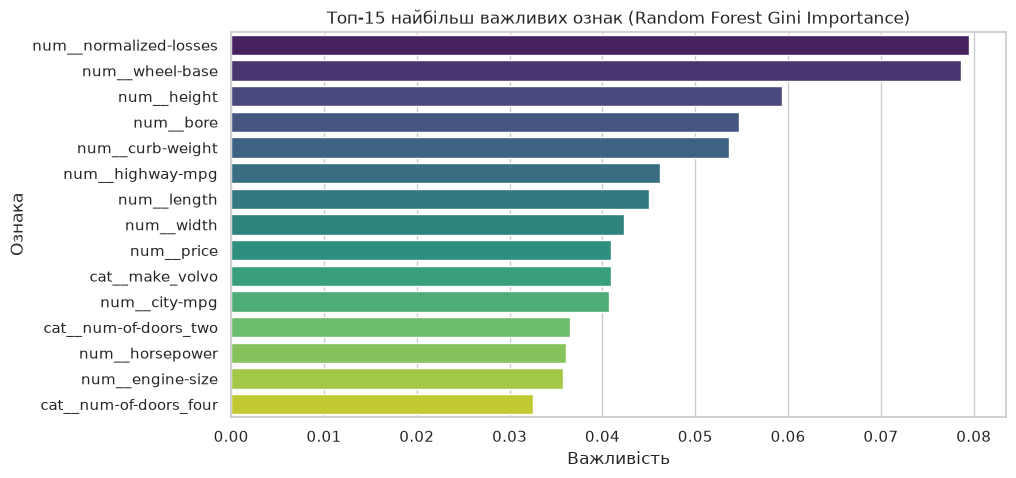

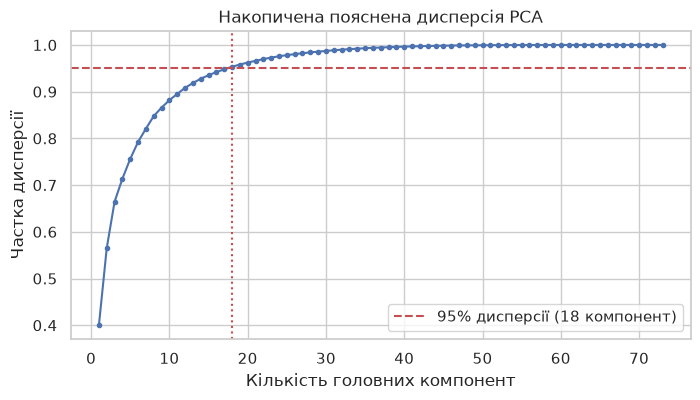

Набір C: 18 компонент покривають 95.33% дисперсії


In [6]:
# --- Набір A: Усі ознаки ---
X_train_A = X_train_balanced.copy()
X_test_A = X_test_prep.copy()

# --- Набір B: Відбір ознак за Feature Importance ---
rf_selector = RandomForestClassifier(n_estimators=100, random_state=42)
rf_selector.fit(X_train_balanced, y_train_balanced)

importances = rf_selector.feature_importances_
threshold = importances.mean()
selected_indices = np.where(importances > threshold)[0]
selected_features = feature_names[selected_indices]

X_train_B = X_train_balanced[:, selected_indices]
X_test_B = X_test_prep[:, selected_indices]

print(f"Набір B: відібрано {X_train_B.shape[1]} ознак із {X_train_A.shape[1]} (поріг = {threshold:.4f})")

# Візуалізація топ-15 ознак
feat_imp_series = pd.Series(importances, index=feature_names).sort_values(ascending=False)
plt.figure(figsize=(10, 5))
sns.barplot(x=feat_imp_series.head(15).values, y=feat_imp_series.head(15).index, palette='viridis')
plt.title("Топ-15 найбільш важливих ознак (Random Forest Gini Importance)")
plt.xlabel("Важливість")
plt.ylabel("Ознака")
plt.show()

# --- Набір C: PCA ---
pca_full = PCA(random_state=42)
pca_full.fit(X_train_balanced)
cum_variance = np.cumsum(pca_full.explained_variance_ratio_)
n_components_95 = np.argmax(cum_variance >= 0.95) + 1

plt.figure(figsize=(8, 4))
plt.plot(range(1, len(cum_variance) + 1), cum_variance, marker='o', markersize=3, color='b')
plt.axhline(y=0.95, color='r', linestyle='--', label=f'95% дисперсії ({n_components_95} компонент)')
plt.axvline(x=n_components_95, color='r', linestyle=':')
plt.title("Накопичена пояснена дисперсія PCA")
plt.xlabel("Кількість головних компонент")
plt.ylabel("Частка дисперсії")
plt.legend()
plt.show()

pca = PCA(n_components=n_components_95, random_state=42)
X_train_C = pca.fit_transform(X_train_balanced)
X_test_C = pca.transform(X_test_prep)
print(f"Набір C: {X_train_C.shape[1]} компонент покривають {cum_variance[n_components_95 - 1] * 100:.2f}% дисперсії")


## Завдання 6. Побудова моделі класифікації
Для чистоти порівняння використовується єдиний алгоритм — `RandomForestClassifier(n_estimators=100, random_state=42)`:
- **Model A:** Усі ознаки $	o$ Classifier
- **Model B:** Відібрані ознаки $	o$ Classifier
- **Model C:** PCA $	o$ Classifier


In [7]:
rf_params = {'n_estimators': 100, 'random_state': 42}

# Навчання трьох моделей
model_A = RandomForestClassifier(**rf_params)
model_A.fit(X_train_A, y_train_balanced)
y_pred_A = model_A.predict(X_test_A)
y_prob_A = model_A.predict_proba(X_test_A)

model_B = RandomForestClassifier(**rf_params)
model_B.fit(X_train_B, y_train_balanced)
y_pred_B = model_B.predict(X_test_B)
y_prob_B = model_B.predict_proba(X_test_B)

model_C = RandomForestClassifier(**rf_params)
model_C.fit(X_train_C, y_train_balanced)
y_pred_C = model_C.predict(X_test_C)
y_prob_C = model_C.predict_proba(X_test_C)

print("Усі три моделі успішно навчено!")


Усі три моделі успішно навчено!


## Завдання 7. Оцінювання моделей
- Обчислення Accuracy, Precision, Recall, F1-score та ROC-AUC (OvR weighted).
- Побудова матриць невідповідностей (Confusion Matrix).
- Зведення результатів у підсумкову таблицю.


,Варіант,Представлення даних,Кількість ознак,Accuracy,Precision,Recall,F1-score,ROC-AUC
0,A,Усі ознаки,73,0.8049,0.8057,0.8049,0.7893,0.9692
1,B,Відібрані ознаки,19,0.8049,0.7878,0.8049,0.7911,0.9689
2,C,PCA,18,0.7317,0.7141,0.7317,0.7161,0.9313


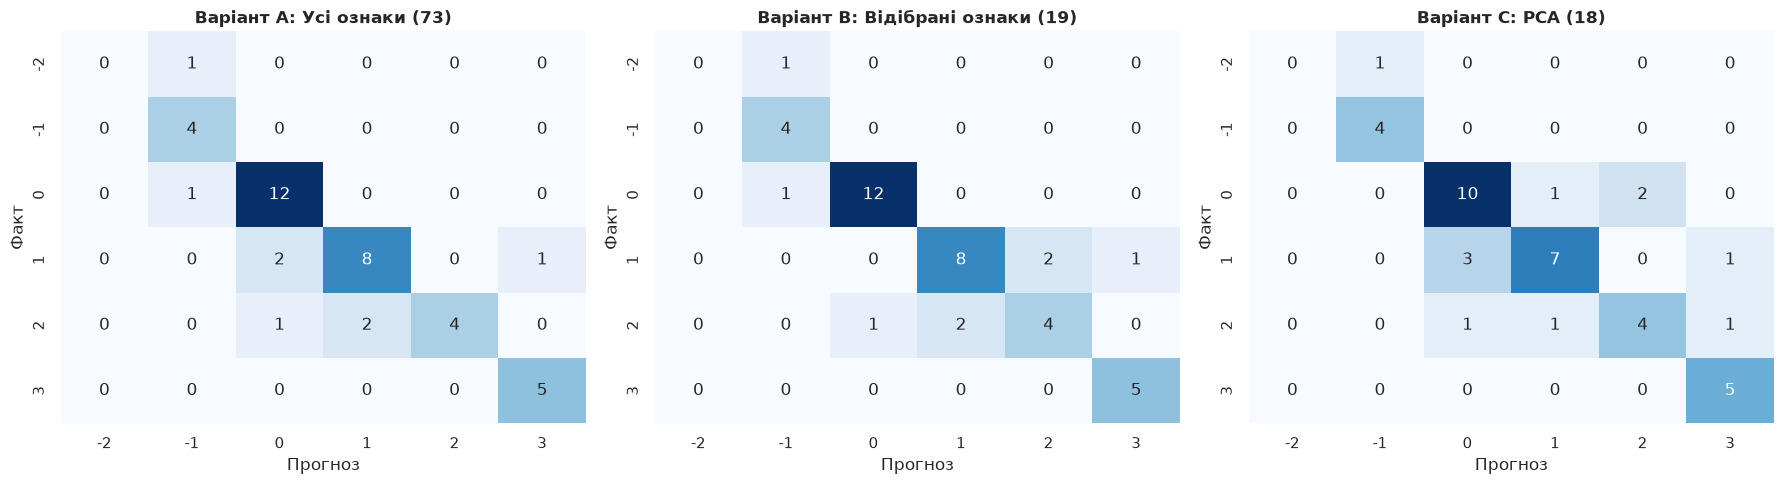

In [8]:
def compute_metrics(y_true, y_pred, y_prob):
    acc = accuracy_score(y_true, y_pred)
    prec = precision_score(y_true, y_pred, average='weighted', zero_division=0)
    rec = recall_score(y_true, y_pred, average='weighted', zero_division=0)
    f1 = f1_score(y_true, y_pred, average='weighted', zero_division=0)
    roc_auc = roc_auc_score(y_true, y_prob, multi_class='ovr', average='weighted')
    return acc, prec, rec, f1, roc_auc

metrics_A = compute_metrics(y_test, y_pred_A, y_prob_A)
metrics_B = compute_metrics(y_test, y_pred_B, y_prob_B)
metrics_C = compute_metrics(y_test, y_pred_C, y_prob_C)

results_table = pd.DataFrame([
    {
        'Варіант': 'A',
        'Представлення даних': 'Усі ознаки',
        'Кількість ознак': X_train_A.shape[1],
        'Accuracy': round(metrics_A[0], 4),
        'Precision': round(metrics_A[1], 4),
        'Recall': round(metrics_A[2], 4),
        'F1-score': round(metrics_A[3], 4),
        'ROC-AUC': round(metrics_A[4], 4)
    },
    {
        'Варіант': 'B',
        'Представлення даних': 'Відібрані ознаки',
        'Кількість ознак': X_train_B.shape[1],
        'Accuracy': round(metrics_B[0], 4),
        'Precision': round(metrics_B[1], 4),
        'Recall': round(metrics_B[2], 4),
        'F1-score': round(metrics_B[3], 4),
        'ROC-AUC': round(metrics_B[4], 4)
    },
    {
        'Варіант': 'C',
        'Представлення даних': 'PCA',
        'Кількість ознак': X_train_C.shape[1],
        'Accuracy': round(metrics_C[0], 4),
        'Precision': round(metrics_C[1], 4),
        'Recall': round(metrics_C[2], 4),
        'F1-score': round(metrics_C[3], 4),
        'ROC-AUC': round(metrics_C[4], 4)
    }
])

display(results_table)

# Візуалізація матриць невідповідностей
classes = sorted(y.unique())
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
cm_models = [
    (y_pred_A, 'Варіант A: Усі ознаки (73)', axes[0]),
    (y_pred_B, 'Варіант B: Відібрані ознаки (19)', axes[1]),
    (y_pred_C, 'Варіант C: PCA (18)', axes[2])
]
for y_pred, title, ax in cm_models:
    cm = confusion_matrix(y_test, y_pred, labels=classes)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
                xticklabels=classes, yticklabels=classes, ax=ax, cbar=False)
    ax.set_title(title, fontsize=12, fontweight='bold')
    ax.set_xlabel('Прогноз')
    ax.set_ylabel('Факт')
plt.tight_layout()
plt.show()


## Завдання 8. Порівняльний аналіз
1. **Чи покращив відбір ознак якість класифікації?**  
   Так, відбір ознак дозволив зберегти показник Accuracy на рівні **80.49%** та дещо підвищити зважений **F1-score (з 0.7893 до 0.7911)**, скоротивши простір ознак майже у 4 рази (з 73 до 19).
2. **Як змінилася точність після зменшення кількості ознак?**  
   Точність (Accuracy) не знизилась і залишилась ідентичною (80.49%), а модель стала менш схильною до перенавчання на рідкісних категоріях.
3. **Скільки ознак можна вилучити без суттєвого погіршення результату?**  
   Вдалося вилучити **54 із 73 ознак (74%)**, залишивши лише 19 найважливіших.
4. **Яку частку дисперсії пояснюють вибрані PCA-компоненти?**  
   18 головних компонент пояснюють **95.33%** сукупної дисперсії даних.
5. **Як PCA вплинув на Accuracy, F1 та ROC-AUC?**  
   Застосування PCA погіршило всі метрики: Accuracy впала на 7.32% (до 73.17%), F1-score знизився до 0.7161, а ROC-AUC — з 0.9692 до 0.9313.
6. **Чи виправдане використання PCA для цього набору даних?**  
   **Не виправдане.** Алгоритм випадкового лісу будує межі паралельно до осей вихідних ознак; штучні лінійні комбінації PCA ускладнюють розбиття простору та руйнують фізичну інтерпретованість характеристик авто.
7. **Який варіант є найкращим?**  
   **Варіант B (відібрані ознаки):** найвищий F1-score (0.7911), максимальна стабільність та компактність.


## Завдання 9. Побудова фінального pipeline

```text
Raw Data
  └──> 1. Cleaning & Imputation (заміна '?', медіани для числових, мода для категоріальних)
  └──> 2. Train/Test Split (80% / 20%, stratify=y)
  └──> 3. Preprocessing (StandardScaler + OneHotEncoder)
  └──> 4. Feature Balancing (SMOTE з k_neighbors=1) [ЛИШЕ НА TRAIN]
  └──> 5. Feature Selection (відбір топ-19 ознак за Feature Importance) [ЛИШЕ НА TRAIN]
  └──> 6. Classification Model (RandomForestClassifier, 100 дерев) [ЛИШЕ НА TRAIN]
  └──> 7. Prediction & Final Evaluation на тестовій вибірці (test залишається незалежним)
```

**Запобігання Data Leakage:**  
Усі параметри перетворень (медіани, моди, `StandardScaler.mean_` / `scale_`, словники категорій `OneHotEncoder`, синтетичні зразки `SMOTE`, оцінки важливості ознак) обчислюються **виключно на навчальній вибірці**. Тестова вибірка залишається недоторканою до моменту фінального тестування.


## Висновки
1. У ході виконання лабораторної роботи досліджено повний цикл інженерії даних для задачі класифікації на прикладі набору даних `Automobile_data.csv` (`target = 'symboling'`).
2. Досліджено три варіанти представлення ознак: повний (73 ознаки), скорочений за Feature Importance (19 ознак), та стиснений через PCA (18 компонент).
3. Найкращим визначено **Варіант B (відібрані ознаки)**: скорочення ознакового простору на 74% дозволило зберегти Accuracy (80.49%) та покращити F1-score до 0.7911.
4. Застосування PCA виявилося недоцільним через втрату інтерпретованості та погіршення метрик на понад 7%.
5. Побудовано надійний кінцевий pipeline із суворим дотриманням ізоляції тестової вибірки для уникнення витоку даних.
